<a href="https://colab.research.google.com/github/Minal7767/CRM_CW1/blob/main/CRM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [75]:
#1.1  Ticker selection and data acquisition

import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from datetime import datetime, timezone
# Record package versions (the brief asks for package versions for reproducibility)
print('pandas', pd.__version__, '| numpy', np.__version__, '| yfinance', yf.__version__)

pandas 2.2.3 | numpy 2.4.6 | yfinance 0.2.66


In [76]:
#S&P 500 ticker list from Wikipedia
url = 'https://en.wikipedia.org/wiki/List_of_S%26P_500_companies'
table = pd.read_html(url, storage_options={"User-Agent": "Mozilla/5.0"})
# the first table is the list of current constituents
sp500_df = table[0]

In [77]:
# Record when the list was retrieved, because the S&P 500 membership changes over time
retrieval_date = datetime.now(timezone.utc).strftime('%Y-%m-%d %H:%M UTC')
sp500_df['Retrieval_Date'] = retrieval_date
# save (store) the ticker list as a CSV file
sp500_df.to_csv('sp500_tickers.csv', index=False)

In [78]:
# turn the Symbol column into a Python list
tickers = sp500_df['Symbol'].tolist()
tickers = [t.replace('.', '-') for t in tickers]
sp500_df['Ticker'] = tickers
# how many tickers were found
print('Tickers retrieved on', retrieval_date, ':', len(tickers))
# preview the first 10 rows
print(sp500_df[['Symbol', 'Security', 'GICS Sector']].head(10))

Tickers retrieved on 2026-11-23 15:06 UTC : 503
  Symbol                Security             GICS Sector
0    MMM                      3M             Industrials
1    AOS             A. O. Smith             Industrials
2    ABT     Abbott Laboratories             Health Care
3   ABBV                  AbbVie             Health Care
4    ACN               Accenture  Information Technology
5   ADBE              Adobe Inc.  Information Technology
6    AMD  Advanced Micro Devices  Information Technology
7    AES         AES Corporation               Utilities
8    AFL                   Aflac              Financials
9      A    Agilent Technologies             Health Care


In [79]:
start = '2021-01-01'
end = '2025-01-01'
benchmark = '^GSPC'
# auto_adjust=False keeps BOTH 'Close' and 'Adj Close' (newer yfinance would otherwise overwrite Close).
# actions=True also returns 'Dividends' and 'Stock Splits', needed for the corporate action checks.
data = yf.download(tickers + [benchmark], start=start, end=end,

                   auto_adjust=False, actions=True)

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['Q', 'FDXF', 'VYLR', 'HONA', 'SNDK']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


In [80]:
 #Preserve the downloaded dataset (snapshot) so the analysis can be reproduced
data.to_pickle('sp500_daily_2021_2024.pkl')
data.stack(level=1, future_stack=True).to_csv('sp500_daily_2021_2024.csv.gz', compression='gzip')

adj = data['Adj Close']            # adjusted close: used for weekly returns and beta
close = data['Close']              # close (split-adjusted in yfinance): used for Monetary
volume = data['Volume']            # volume: used for RFM
splits = data['Stock Splits'] if 'Stock Splits' in data.columns.get_level_values(0) else adj * 0
dividends = data['Dividends'] if 'Dividends' in data.columns.get_level_values(0) else adj * 0
print('Shape of Adj Close table (dates x tickers):', adj.shape)
print('First and last trading dates:', adj.index.min().date(), adj.index.max().date())
# preview: first 5 dates and first 5 tickers
print(adj.iloc[:5, :5])

Shape of Adj Close table (dates x tickers): (1005, 504)
First and last trading dates: 2021-01-04 2024-12-31
Ticker               A        AAPL       ABBV        ABNB        ABT
Date                                                                
2021-01-04  114.009140  125.537125  84.219139  139.149994  97.269699
2021-01-05  114.941269  127.089218  85.090012  148.300003  98.473206
2021-01-06  118.093224  122.811188  84.354973  142.770004  98.268173
2021-01-07  121.235588  127.001961  85.257812  151.270004  99.222046
2021-01-08  122.100449  128.098114  85.705208  149.770004  99.498390


In [81]:
#Task 1.2  Data validation and alignment

In [82]:
# count repeated dates
print('Duplicate dates in the download:', data.index.duplicated().sum())
# keep only the first copy of a date
data = data[~data.index.duplicated(keep='first')]
# rebuild the field tables
adj, close, volume = data['Adj Close'], data['Close'], data['Volume']
# same for the split table
splits = splits[~splits.index.duplicated(keep='first')]

Duplicate dates in the download: 0


In [83]:
# Trading calendar = dates on which the benchmark has a price
market_dates = adj[benchmark].dropna().index

print('Benchmark trading days:', len(market_dates))

Benchmark trading days: 1005


In [84]:
# Transpose like the seminar: rows = tickers, columns = dates
# adjusted close of the shares,volume only
df1 = adj.drop(columns=benchmark).T
close1 = close.drop(columns=benchmark).T
vol1 = volume.drop(columns=benchmark).T

print('Before validation:', df1.shape)

Before validation: (503, 1005)


In [85]:
# empty table with one row per ticker
check = pd.DataFrame(index=df1.index)
# True if yfinance returned no prices at all
check['no_data'] = df1.isna().all(axis=1)
# first date with a price
check['first_date'] = df1.apply(lambda row: row.first_valid_index(), axis=1)
# last date with a price
check['last_date'] = df1.apply(lambda row: row.last_valid_index(), axis=1)
#prices on days when the benchmark did not trade would not align with the benchmark
check['dates_not_in_benchmark'] = df1.loc[:, ~df1.columns.isin(market_dates)].notna().sum(axis=1)
#trading days with no Adj Close
check['missing_adj_close'] = df1[market_dates].isna().sum(axis=1)
#trading days with no Close
check['missing_close'] = close1[market_dates].isna().sum(axis=1)
#trading days with no Volume
check['missing_volume'] = vol1[market_dates].isna().sum(axis=1)
#prices of zero or below are errors
check['nonpositive_prices'] = ((df1 <= 0) | (close1 <= 0)).sum(axis=1)
#volume of zero or below is an error
check['zero_or_negative_volume'] = (vol1 <= 0).sum(axis=1)

In [86]:
# Corporate actions
daily_adj_ret = df1.T.pct_change(fill_method=None)
daily_close_ret = close1.T.pct_change(fill_method=None)
split_days = splits.drop(columns=benchmark, errors='ignore').reindex(daily_close_ret.index).fillna(0) > 0
adj_factor = (df1 / close1).T                       # Adj Close / Close, should only rise over time
check['splits'] = split_days.sum()
check['dividend_days'] = (dividends.drop(columns=benchmark, errors='ignore') > 0).sum()
check['split_not_in_close'] = (split_days & (daily_close_ret.abs() > 0.40)).sum()
check['adj_factor_problems'] = ((adj_factor.pct_change(fill_method=None) < -0.02) | (adj_factor > 1.0001)).sum()
check['moves_over_40pct'] = (daily_adj_ret.abs() > 0.40).sum()     # listed for review only
#Apply the rules: the first rule a share fails becomes its exclusion reason
def exclusion_reason(r):
    if r['no_data']:                            return 'no data returned by yfinance'
    if r['dates_not_in_benchmark'] > 0:         return 'dates not in benchmark calendar'
    if r['first_date'] > market_dates[0]:       return 'history starts ' + str(r['first_date'].date()) + ' (unequal history)'
    if r['last_date'] < market_dates[-1]:       return 'history ends ' + str(r['last_date'].date()) + ' (unequal history)'
    if r['missing_adj_close'] + r['missing_close'] + r['missing_volume'] > 0:
                                                return 'missing prices or volume'
    if r['nonpositive_prices'] > 0:             return 'non-positive price'
    if r['zero_or_negative_volume'] > 0:        return 'zero or negative volume'
    if r['split_not_in_close'] > 0 or r['adj_factor_problems'] > 0:
                                                return 'corporate action not adjusted consistently'
    return ''
# apply the rules to every share
check['Reason'] = check.apply(exclusion_reason, axis=1)
check['Included'] = check['Reason'] == ''
check = check.join(sp500_df.set_index('Ticker')[['Security', 'GICS Sector']])
check.to_csv('inclusion_exclusion_log.csv')
# list of retained tickers
valid = check.index[check['Included']].tolist()
# retained prices only; no ffill or bfill
df_clean = df1.loc[valid, market_dates]              # no ffill / bfill
print('After validation:', df_clean.shape)
print('Shares removed:', len(df1) - len(valid))
# the exclusion log on screen
print(check.loc[~check['Included'], ['Security', 'Reason']])
print('Splits in the period:', int(check['splits'].sum()),

      '| moves over 40% to review:', check.loc[check['moves_over_40pct'] > 0].index.tolist())

After validation: (486, 1005)
Shares removed: 17
                    Security                                       Reason
Ticker                                                                   
APP                 AppLovin  history starts 2021-04-15 (unequal history)
CEG     Constellation Energy  history starts 2022-01-19 (unequal history)
COIN                Coinbase  history starts 2021-04-14 (unequal history)
EXE            Expand Energy  history starts 2021-02-10 (unequal history)
FDXF           FedEx Freight                 no data returned by yfinance
FERG    Ferguson Enterprises                      zero or negative volume
GEHC           GE HealthCare  history starts 2022-12-15 (unequal history)
GEV               GE Vernova  history starts 2024-03-27 (unequal history)
HONA     Honeywell Aerospace                 no data returned by yfinance
HOOD       Robinhood Markets  history starts 2021-07-29 (unequal history)
Q          Qnity Electronics                 no data returned b

In [87]:
# Task 1.3  Mean weekly return

In [88]:
def calculate_weekly_returns(df1, shares=None):
    """Weekly returns from df1 (tickers as rows, dates as columns)."""
    prices = df1 if shares is None else df1.loc[shares]
    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    prices = prices.sort_index()

    weekly_prices = prices.resample('W-FRI').last()

In [89]:
def calculate_weekly_returns(df1, shares=None):
    """Weekly returns from df1 (tickers as rows, dates as columns)."""
    # all shares, or only the ones asked for
    prices = df1 if shares is None else df1.loc[shares]
    # back to dates as rows
    prices = prices.T.copy()
    prices.index = pd.to_datetime(prices.index)
    # oldest date first
    prices = prices.sort_index()

    weekly_prices = prices.resample('W-FRI').last()

    # keep only full calendar weeks (Saturday to Friday) inside the study period
    week_start = weekly_prices.index - pd.Timedelta(days=6)
    weekly_prices = weekly_prices[(week_start >= pd.Timestamp(start)) & (weekly_prices.index < pd.Timestamp(end))]

    # No week may be missing a price, and weeks must be exactly 7 days apart
    assert weekly_prices.notna().all().all(), 'missing weekly price'
    assert (weekly_prices.index.to_series().diff().dropna() == pd.Timedelta(days=7)).all(), 'missing week'
    # first week is only the base price
    return weekly_prices.pct_change(fill_method=None).iloc[1:]

In [90]:
# Shares and benchmark together, so they get identical week labels
prices_all = pd.concat([df_clean, adj.loc[market_dates, [benchmark]].T])
all_weekly = calculate_weekly_returns(prices_all)
# benchmark returns
market_weekly_returns = all_weekly[[benchmark]]          # was missing in the seminar notebook
weekly_returns = all_weekly.drop(columns=benchmark)
assert weekly_returns.index.equals(market_weekly_returns.index)

print('Weekly returns:', weekly_returns.index[0].date(), 'to', weekly_returns.index[-1].date(),

      '|', len(weekly_returns), 'weeks x', weekly_returns.shape[1], 'shares')

Weekly returns: 2021-01-15 to 2024-12-27 | 207 weeks x 486 shares


In [91]:
#1.3.1 arithmetic mean weekly return (return feature for clustering)

mean_weekly_return = weekly_returns.mean()

In [92]:
# 1.3.2 weekly beta = cov(share, market) / var(market)  (seminar function)
def calculate_weekly_beta(weekly_returns, market_returns, min_weeks=52):
    if min_weeks < 2:
        raise ValueError("min_weeks must be at least 2.")
    results = []
    for share in weekly_returns.columns:
        paired = pd.concat([weekly_returns[share].rename("share"),
                            market_returns.rename("market")], axis=1
                           ).replace([np.inf, -np.inf], np.nan).dropna()
        variance = paired["market"].var(ddof=1)
        beta = np.nan
        if len(paired) >= min_weeks and variance > 0:
            beta = paired["share"].cov(paired["market"]) / variance
        results.append({"Share": share, "Beta": beta, "Paired_weeks": len(paired)})
    return pd.DataFrame(results, columns=["Share", "Beta", "Paired_weeks"]).set_index("Share")

beta_df = calculate_weekly_beta(weekly_returns, market_weekly_returns[benchmark])

beta_df['Mean_Weekly_Return'] = mean_weekly_return

In [93]:
# Checks: beta equals the regression slope; the benchmark's own beta is 1
slope = [np.polyfit(market_weekly_returns[benchmark], weekly_returns[s], 1)[0] for s in weekly_returns.columns]
assert np.allclose(slope, beta_df['Beta'])
assert np.isclose(calculate_weekly_beta(market_weekly_returns, market_weekly_returns[benchmark])['Beta'].iloc[0], 1)
# save the weekly return table
all_weekly.to_csv('weekly_returns.csv')
# brief asks for this count
print('Aligned weekly observations per share:', beta_df['Paired_weeks'].unique())
# summary of beta and mean weekly return
print(beta_df.describe())

Aligned weekly observations per share: [207]
             Beta  Paired_weeks  Mean_Weekly_Return
count  486.000000         486.0          486.000000
mean     0.973695         207.0            0.002857
std      0.407339           0.0            0.002652
min      0.055453         207.0           -0.004468
25%      0.666599         207.0            0.001182
50%      0.950610         207.0            0.002619
75%      1.179538         207.0            0.004207
max      3.778560         207.0            0.017772


In [94]:
# Task 1.4  Adapted RFM

In [95]:
close_clean = close.loc[market_dates, valid]
vol_clean = volume.loc[market_dates, valid]

In [96]:
# Observation date: final common completed trading date
complete = close_clean.notna().all(axis=1) & vol_clean.notna().all(axis=1)
obs_date = complete[complete].index.max()
sessions = market_dates[market_dates <= obs_date]
last60 = sessions[-60:]
# latest 60 trading sessions
print('Observation date:', obs_date.date(), '| 60-session window:', last60[0].date(), 'to', last60[-1].date())
baseline = vol_clean.shift(1).rolling(20, min_periods=20).mean()   # preceding 20 sessions
threshold = 2 * baseline
# event threshold = twice the baseline
high_volume = (vol_clean > threshold) & baseline.notna()

Observation date: 2024-12-31 | 60-session window: 2024-10-07 to 2024-12-31


In [97]:
# history check: every day in the 60 window has a full 20-session baseline
assert baseline.loc[last60].notna().all().all()

In [98]:
# 1.4.1 Recency: calendar days from the latest event to the observation date (no event -> NaN, not 0)

def last_event(col):
    days = col.loc[:obs_date]
    return days.index[days].max() if days.any() else pd.NaT
last_event_date = high_volume.apply(last_event)
recency = (obs_date - last_event_date).dt.days

In [99]:
# 1.4.2 Frequency: number of high volume DAYS in the latest 60 sessions
frequency = high_volume.loc[last60].sum()

In [100]:
# 1.4.3 Monetary: sum of Close x Volume over the latest 60 sessions (USD)
monetary = (close_clean * vol_clean).loc[last60].sum()
rfm = pd.DataFrame({'Last_Event_Date': last_event_date, 'Recency': recency,
                    'Frequency': frequency, 'Monetary': monetary})
print('Shares with no high volume event (excluded from RFM clustering):',
      rfm.index[rfm['Recency'].isna()].tolist())
print(rfm.describe()) # summary of R, F and M

Shares with no high volume event (excluded from RFM clustering): []
           Last_Event_Date     Recency   Frequency      Monetary
count                  486  486.000000  486.000000  4.860000e+02
mean   2024-12-10 14:13:20   20.407407    2.989712  3.940419e+10
min    2024-05-23 00:00:00    4.000000    0.000000  1.297483e+09
25%    2024-12-16 06:00:00   11.000000    2.000000  1.019517e+10
50%    2024-12-20 00:00:00   11.000000    3.000000  1.668382e+10
75%    2024-12-20 00:00:00   14.750000    4.000000  3.227689e+10
max    2024-12-27 00:00:00  222.000000    8.000000  1.847697e+12
std                    NaN   21.342438    1.330800  1.291388e+11


In [101]:
# Task 1.5  Worked example, checks, feature summaries and feature table

In [102]:
# Threshold alignment check on random share-days: threshold uses the 20 days BEFORE the day
rng = np.random.default_rng(1)
for _ in range(1000):
    i = rng.integers(20, len(market_dates)); s = rng.choice(valid)
    assert np.isclose(threshold[s].iloc[i], 2 * vol_clean[s].iloc[i - 20:i].mean())

In [103]:
# Worked RFM example for one share
ex = 'AAPL' if 'AAPL' in valid else valid[0]
print('Worked example:', ex, '| observation date', obs_date.date())
d = rfm.loc[ex, 'Last_Event_Date']
if pd.notna(d):
    print(f'Recency: latest event {d.date()}, volume {vol_clean.at[d, ex]:,.0f} > threshold '
          f'{threshold.at[d, ex]:,.0f}; R = {obs_date.date()} - {d.date()} = {rfm.loc[ex, "Recency"]:.0f} days')
# Day-by-day table for the 60-session window, showing how F and M are built
example = pd.DataFrame({'Close': close_clean[ex], 'Volume': vol_clean[ex], 'Baseline_20': baseline[ex],
                        'Threshold': threshold[ex], 'High_Volume': high_volume[ex],
                        'Close_x_Volume': close_clean[ex] * vol_clean[ex]}).loc[last60]
print('Frequency: high volume days in the 60 sessions =', int(example['High_Volume'].sum()),
      [x.date() for x in example.index[example['High_Volume']]])
print(f"Monetary: sum of 60 x (Close x Volume) = ${example['Close_x_Volume'].sum():,.0f}")
print(example.head(10))

Worked example: AAPL | observation date 2024-12-31
Recency: latest event 2024-12-20, volume 147,495,300 > threshold 90,009,210; R = 2024-12-31 - 2024-12-20 = 11 days
Frequency: high volume days in the 60 sessions = 2 [datetime.date(2024, 11, 25), datetime.date(2024, 12, 20)]
Monetary: sum of 60 x (Close x Volume) = $623,303,377,707
                 Close    Volume  Baseline_20    Threshold  High_Volume  Close_x_Volume
Date                                                                                   
2024-10-07  221.690002  39505400   61024170.0  122048340.0        False    8.757952e+09
2024-10-08  225.770004  31855700   59640440.0  119280880.0        False    7.192062e+09
2024-10-09  229.539993  33591100   58653675.0  117307350.0        False    7.710501e+09
2024-10-10  229.039993  28183500   58103875.0  116207750.0        False    6.455149e+09
2024-10-11  227.550003  31759200   57640270.0  115280540.0        False    7.226806e+09
2024-10-14  231.300003  39882100   57389900.0  114

In [104]:
# Final feature table: one row per included share
features = (check.loc[valid, ['Security', 'GICS Sector']]
            .join(beta_df[['Mean_Weekly_Return', 'Beta', 'Paired_weeks']])
            .join(rfm))
features['Common_Set'] = features[['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']].notna().all(axis=1)
features.to_csv('task1_feature_table.csv')
cols = ['Mean_Weekly_Return', 'Beta', 'Recency', 'Frequency', 'Monetary']
#count, mean, std, min, quartiles and max of each feature
summary = features[cols].describe().T
print('Shares in feature table:', len(features), '| common valid set:', int(features['Common_Set'].sum()))
print(summary)

Shares in feature table: 486 | common valid set: 486
                    count          mean           std           min           25%           50%           75%           max
Mean_Weekly_Return  486.0  2.857173e-03  2.651609e-03 -4.468094e-03  1.181530e-03  2.618932e-03  4.207323e-03  1.777248e-02
Beta                486.0  9.736953e-01  4.073389e-01  5.545338e-02  6.665989e-01  9.506099e-01  1.179538e+00  3.778560e+00
Recency             486.0  2.040741e+01  2.134244e+01  4.000000e+00  1.100000e+01  1.100000e+01  1.475000e+01  2.220000e+02
Frequency           486.0  2.989712e+00  1.330800e+00  0.000000e+00  2.000000e+00  3.000000e+00  4.000000e+00  8.000000e+00
Monetary            486.0  3.940419e+10  1.291388e+11  1.297483e+09  1.019517e+10  1.668382e+10  3.227689e+10  1.847697e+12


In [105]:
#Task 2

In [106]:
#Task 2.1  Feature preparation

In [107]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import scipy
from sklearn.preprocessing import StandardScaler
# Package versions are printed because the brief asks for them
print('pandas', pd.__version__, '| numpy', np.__version__,
      '| scikit-learn', sklearn.__version__, '| scipy', scipy.__version__)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
# one seed used for every random step in Task 2
SEED = 42
features = pd.read_csv('task1_feature_table.csv', index_col=0)
rr_cols = ['Mean_Weekly_Return', 'Beta']
rfm_cols = ['Recency', 'Frequency', 'Monetary']

pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1 | scipy 1.16.3


In [108]:
# Shares with no high volume event (Recency missing) are excluded here, not filled with 0.
# treat infinite values as missing
features = features.replace([np.inf, -np.inf], np.nan)
# drop shares with any missing feature
common = features.dropna(subset=rr_cols + rfm_cols).copy()
print('Shares in Task 1 feature table:', len(features))
print('Shares in common valid set   :', len(common))
print('Excluded (missing feature)   :', features.index.difference(common.index).tolist())

Shares in Task 1 feature table: 486
Shares in common valid set   : 486
Excluded (missing feature)   : []


In [109]:
# ---- Skew and outlier inspection (original units) ----
# lower and upper quartiles
# interquartile range
def outlier_summary(df):
    q1, q3 = df.quantile(0.25), df.quantile(0.75)
    iqr = q3 - q1
    z = (df - df.mean()) / df.std(ddof=0)
    return pd.DataFrame({'skew': df.skew(),
                         'min': df.min(), 'median': df.median(), 'max': df.max(),
                         'IQR_outliers': ((df < q1 - 1.5 * iqr) | (df > q3 + 1.5 * iqr)).sum(),
                         'abs_z_over_3': (z.abs() > 3).sum()})
print('\nSkew and outliers before transformation:')
print(outlier_summary(common[rr_cols + rfm_cols]).round(4))


Skew and outliers before transformation:
                       skew           min        median           max  IQR_outliers  abs_z_over_3
Mean_Weekly_Return   0.8675 -4.500000e-03  2.600000e-03  1.780000e-02            15             6
Beta                 1.1036  5.550000e-02  9.506000e-01  3.778600e+00            10             2
Recency              3.6458  4.000000e+00  1.100000e+01  2.220000e+02           115            11
Frequency            0.4247  0.000000e+00  3.000000e+00  8.000000e+00             2             5
Monetary            11.6838  1.297483e+09  1.668382e+10  1.847697e+12            45             5


In [110]:
# Effect of log1p on each RFM variable (log1p is only REQUIRED for Monetary)
log_check = pd.DataFrame({'skew_raw': common[rfm_cols].skew(),
                          'skew_log1p': np.log1p(common[rfm_cols]).skew()})
print('\nSkew of RFM variables, raw vs log1p:')
print(log_check.round(3))


Skew of RFM variables, raw vs log1p:
           skew_raw  skew_log1p
Recency       3.646       1.583
Frequency     0.425      -0.928
Monetary     11.684       1.079


In [111]:
# shares, not data errors after Task 1 validation); their effect is seen in cluster sizes.
z_all = (common[rr_cols + rfm_cols] - common[rr_cols + rfm_cols].mean()) / common[rr_cols + rfm_cols].std(ddof=0)
print('\nShares with |z| > 3 on any raw feature:')
print(common.loc[(z_all.abs() > 3).any(axis=1), rr_cols + rfm_cols])


Shares with |z| > 3 on any raw feature:
        Mean_Weekly_Return      Beta  Recency  Frequency      Monetary
Ticker                                                                
AAPL              0.003930  1.174836       11          2  6.233034e+11
AMZN              0.002681  1.386667       11          5  4.681770e+11
APD               0.001183  0.708583       85          1  2.662261e+10
AZO               0.005274  0.758424       98          0  2.482392e+10
CB                0.003508  0.573060      102          0  2.523472e+10
CI                0.002034  0.411722       13          8  3.789504e+10
COR               0.004373  0.548114      102          0  1.759981e+10
CVNA              0.010964  3.778560       36          3  3.836519e+10
DUK               0.002005  0.353152      102          0  2.274797e+10
FCX               0.003368  1.492185       96          0  2.847770e+10
FIX               0.011297  1.336793       64          2  8.597492e+09
FOXA              0.003324  0.460583

In [112]:
LOG_RECENCY = False

In [113]:
# risk and return matrix
X_rr = common[rr_cols].copy()
# trading activity matrix
X_rfm = common[rfm_cols].copy()
X_rfm['Monetary'] = np.log1p(X_rfm['Monetary'])
if LOG_RECENCY:
    X_rfm['Recency'] = np.log1p(X_rfm['Recency'])
X_rfm = X_rfm.rename(columns={'Monetary': 'log1p_Monetary'})

In [114]:
# ---- Standardise each matrix separately (mean 0, std 1) ----
scaler_rr = StandardScaler()
scaler_rfm = StandardScaler()
Z_rr = pd.DataFrame(scaler_rr.fit_transform(X_rr), index=X_rr.index, columns=X_rr.columns)
Z_rfm = pd.DataFrame(scaler_rfm.fit_transform(X_rfm), index=X_rfm.index, columns=X_rfm.columns)
print('\nStandardised risk and return matrix:', Z_rr.shape)
print(Z_rr.describe().round(3))
print('\nStandardised trading activity matrix:', Z_rfm.shape)
print(Z_rfm.describe().round(3))


Standardised risk and return matrix: (486, 2)
       Mean_Weekly_Return     Beta
count             486.000  486.000
mean               -0.000    0.000
std                 1.001    1.001
min                -2.765   -2.257
25%                -0.633   -0.755
50%                -0.090   -0.057
75%                 0.510    0.506
max                 5.631    6.893

Standardised trading activity matrix: (486, 3)
       Recency  Frequency  log1p_Monetary
count  486.000    486.000         486.000
mean    -0.000     -0.000          -0.000
std      1.001      1.001           1.001
min     -0.770     -2.249          -2.867
25%     -0.441     -0.744          -0.677
50%     -0.441      0.008          -0.153
75%     -0.265      0.760           0.548
max      9.455      3.769           4.848


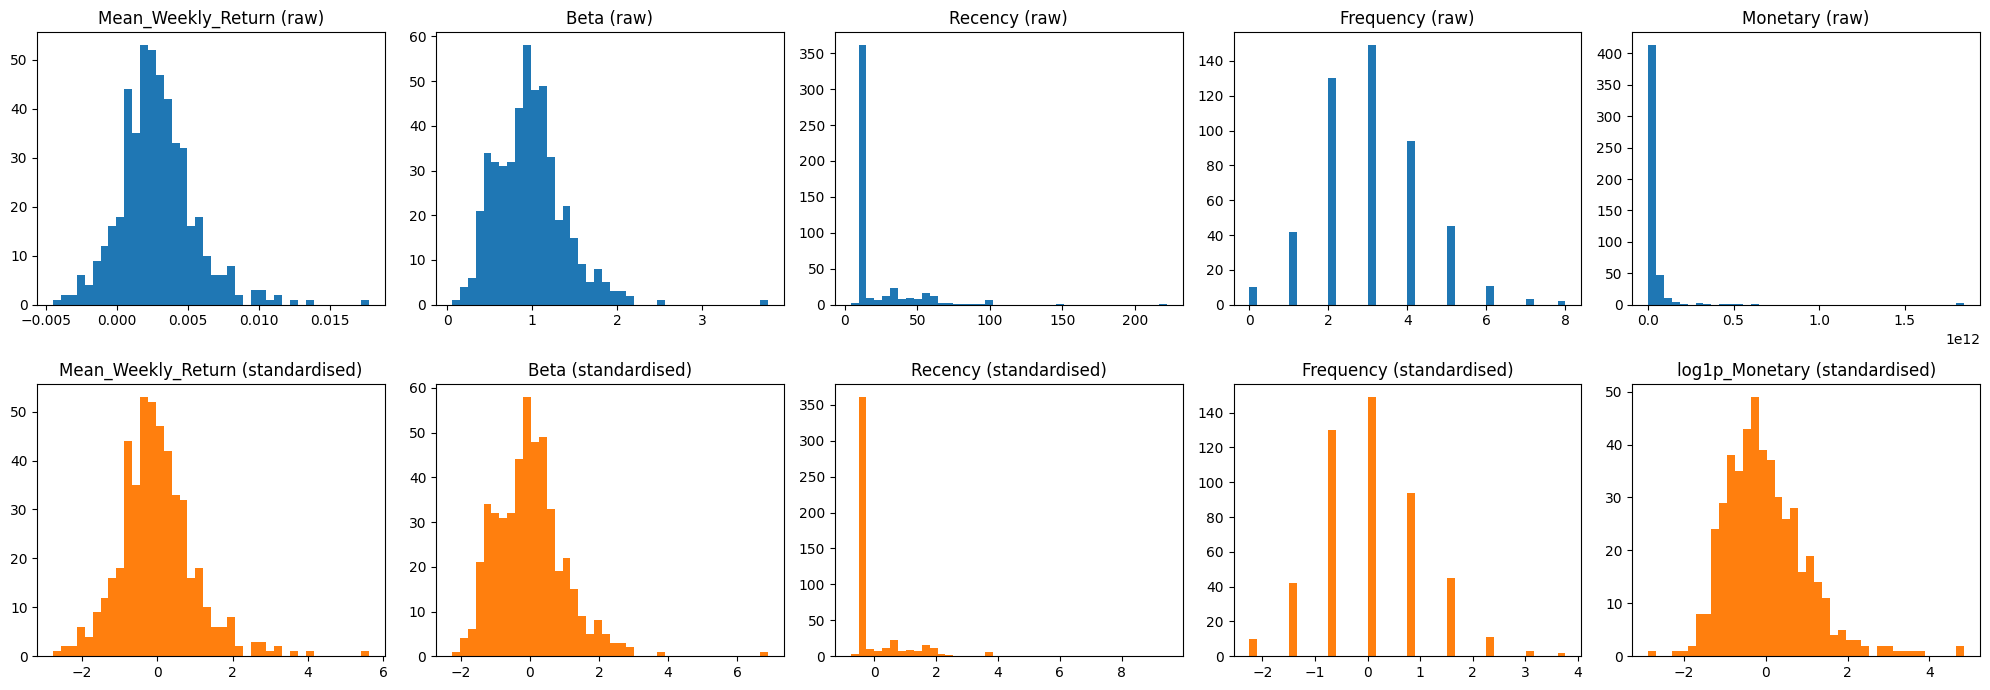

In [115]:
# ---- Distributions before and after preparation ----
fig, axes = plt.subplots(2, 5, figsize=(20, 7))
for i, c in enumerate(rr_cols + rfm_cols):
    axes[0, i].hist(common[c], bins=40)
    axes[0, i].set_title(c + ' (raw)')
for i, c in enumerate(list(Z_rr.columns) + list(Z_rfm.columns)):
    data_z = Z_rr[c] if c in Z_rr.columns else Z_rfm[c]
    axes[1, i].hist(data_z, bins=40, color='tab:orange')
    axes[1, i].set_title(c + ' (standardised)')
plt.tight_layout()
plt.savefig('task2_1_feature_distributions.png', dpi=150)
plt.show()

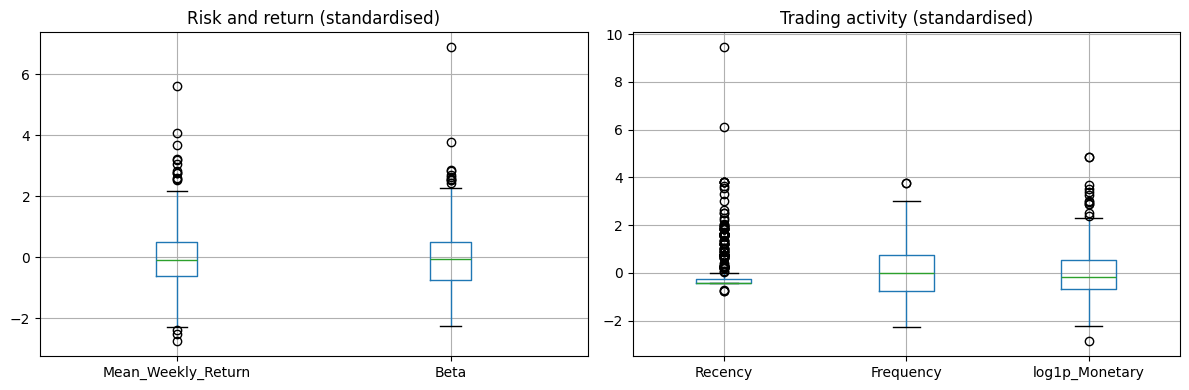

In [116]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
Z_rr.boxplot(ax=axes[0]); axes[0].set_title('Risk and return (standardised)')
Z_rfm.boxplot(ax=axes[1]); axes[1].set_title('Trading activity (standardised)')
plt.tight_layout()
plt.savefig('task2_1_boxplots.png', dpi=150)
plt.show()

In [117]:
X_rr.join(X_rfm).to_csv('task2_prepared_features.csv')

In [118]:
# Task 2.2  Agglomerative clustering

In [119]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score
# cluster counts 2 to 8 as required
K_RANGE = range(2, 9)

In [120]:
def profile(labels, cols, data=common):
    """Mean of each original-unit feature by cluster, plus cluster size."""
    # cluster averages
    p = data[cols].groupby(labels).mean()
    p.insert(0, 'n_shares', pd.Series(labels).value_counts().sort_index().values)
    return p

In [121]:
def suggest_k(table, min_size):
    """Highest silhouette among k whose smallest cluster has at least min_size shares.
    Only a starting point: confirm with the dendrogram gaps and the profiles."""
    ok = table[table['smallest_cluster'] >= min_size]
    ok = ok if len(ok) else table
    return int(ok['silhouette'].idxmax())

In [122]:
# a "cluster" of 1-4 shares is an outlier group
MIN_SIZE = max(5, int(0.02 * len(common)))
print('Minimum useful cluster size:', MIN_SIZE)

Minimum useful cluster size: 9


In [123]:
def ward_analysis(Z, name, cols):
    link = linkage(Z.values, method='ward', metric='euclidean')
    rows, labels_by_k = [], {}
    for k in K_RANGE:
        labels = fcluster(link, t=k, criterion='maxclust')
        sizes = pd.Series(labels).value_counts().sort_index()
        labels_by_k[k] = labels
        rows.append({'k': k,
                     'silhouette': silhouette_score(Z.values, labels),
                     'merge_height': link[-(k - 1), 2],          # height of the merge that makes k-1 from k
                     'smallest_cluster': sizes.min(),
                     'largest_cluster': sizes.max(),
                     'sizes': sizes.tolist()})
    table = pd.DataFrame(rows).set_index('k')
    print(f'\nWard {name}: cluster count comparison')
    print(table.round(3))
    for k in K_RANGE:                                           # profiles so each k can be interpreted
        print(f'\nWard {name}, k={k} profile (original units):')
        print(profile(labels_by_k[k], cols).round(4))
    return link, table, labels_by_k

In [124]:
link_rr, ward_rr_table, ward_rr_labels = ward_analysis(Z_rr, 'risk and return', rr_cols)
link_rfm, ward_rfm_table, ward_rfm_labels = ward_analysis(Z_rfm, 'trading activity', rfm_cols)


Ward risk and return: cluster count comparison
   silhouette  merge_height  smallest_cluster  largest_cluster                             sizes
k                                                                                               
2       0.339        23.073                92              394                         [92, 394]
3       0.274        18.803                92              230                    [92, 164, 230]
4       0.282        14.210                48              182                [92, 164, 48, 182]
5       0.304        12.669                48              182             [92, 66, 98, 48, 182]
6       0.320        11.601                 5              182          [5, 87, 66, 98, 48, 182]
7       0.324         8.342                 5              160      [5, 87, 66, 98, 48, 22, 160]
8       0.321         8.308                 5              160  [5, 56, 31, 66, 98, 48, 22, 160]

Ward risk and return, k=2 profile (original units):
   n_shares  Mean_Weekly_R

In [125]:
# ---- Selected cluster counts ----
# the tables, dendrograms and profiles if another k is easier to justify
k_ward_rr = suggest_k(ward_rr_table, MIN_SIZE)
k_ward_rfm = suggest_k(ward_rfm_table, MIN_SIZE)
print('\nSelected Ward k  | risk and return:', k_ward_rr, '| trading activity:', k_ward_rfm)


Selected Ward k  | risk and return: 2 | trading activity: 2


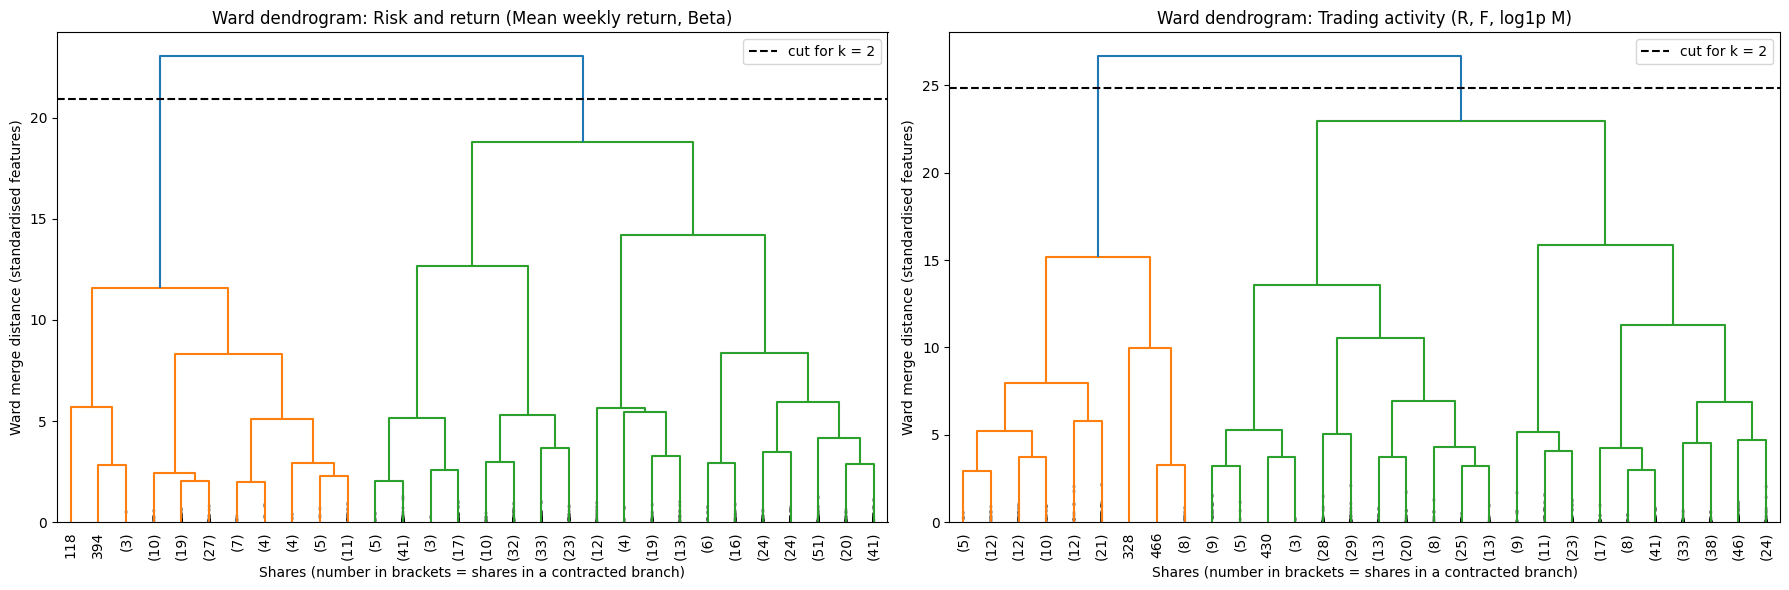

In [126]:
# ---- Dendrograms (one per matrix), last 30 merges shown so the tree is readable ----

fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, link, name, k in [(axes[0], link_rr, 'Risk and return (Mean weekly return, Beta)', k_ward_rr),
                          (axes[1], link_rfm, 'Trading activity (R, F, log1p M)', k_ward_rfm)]:
    cut = (link[-k, 2] + link[-(k - 1), 2]) / 2               # any height between these gives k groups
    dendrogram(link, truncate_mode='lastp', p=30, show_contracted=True,
               color_threshold=cut, leaf_rotation=90, ax=ax)
    ax.axhline(cut, color='black', linestyle='--', label=f'cut for k = {k}')    # mark the selected cut
    ax.set_title('Ward dendrogram: ' + name)
    ax.set_xlabel('Shares (number in brackets = shares in a contracted branch)')
    ax.set_ylabel('Ward merge distance (standardised features)')
    ax.legend()
plt.tight_layout()
plt.savefig('task2_2_dendrograms.png', dpi=150)
plt.show()

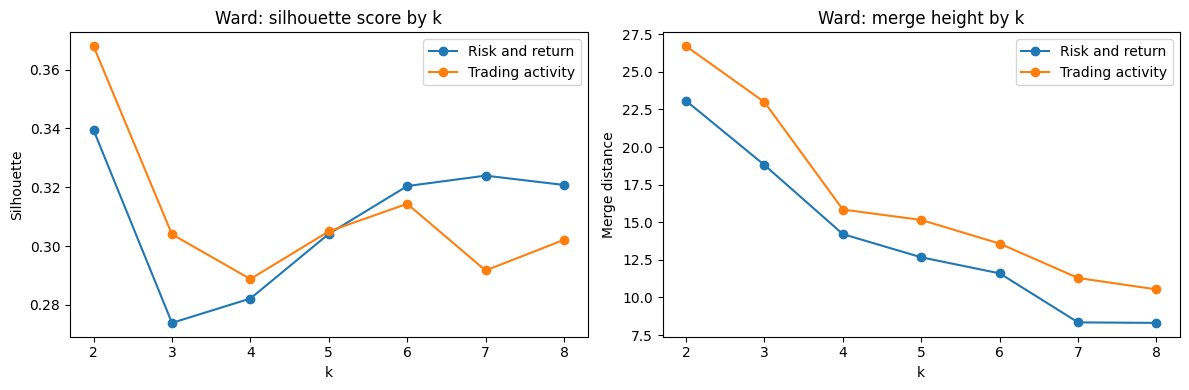

In [127]:
# ---- Silhouette and merge height by k ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for t, name in [(ward_rr_table, 'Risk and return'), (ward_rfm_table, 'Trading activity')]:
    axes[0].plot(t.index, t['silhouette'], marker='o', label=name)
    axes[1].plot(t.index, t['merge_height'], marker='o', label=name)
axes[0].set_title('Ward: silhouette score by k'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Silhouette')
axes[1].set_title('Ward: merge height by k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Merge distance')
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig('task2_2_ward_k_selection.png', dpi=150)
plt.show()

In [128]:
# store selected Ward risk-return clusters
common['Ward_RR'] = ward_rr_labels[k_ward_rr]
# store selected Ward trading-activity clusters
common['Ward_RFM'] = ward_rfm_labels[k_ward_rfm]
# k comparison tables as evidence
ward_rr_table.to_csv('task2_2_ward_rr_k_table.csv')
ward_rfm_table.to_csv('task2_2_ward_rfm_k_table.csv')

In [129]:
# Task 2.3  K means clustering

In [130]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
# 50 k-means++ starts, the lowest-inertia run is kept
N_INIT = 50

In [131]:
def kmeans_analysis(Z, name, cols):
    rows, labels_by_k = [], {}
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED)     # seeded, multiple initialisations
        labels = km.fit_predict(Z.values) + 1           # clusters numbered from 1 like Ward
        sizes = pd.Series(labels).value_counts().sort_index()
        labels_by_k[k] = labels
        rows.append({'k': k, 'inertia': km.inertia_,
                     'silhouette': silhouette_score(Z.values, labels),
                     'smallest_cluster': sizes.min(), 'largest_cluster': sizes.max(),
                     'sizes': sizes.tolist()})
    table = pd.DataFrame(rows).set_index('k')
    print(f'\nK means {name}: k comparison (n_init={N_INIT}, random_state={SEED})')
    print(table.round(3))
    for k in K_RANGE:
        print(f'\nK means {name}, k={k} profile (original units):')
        print(profile(labels_by_k[k], cols).round(4))
    return table, labels_by_k

In [132]:
km_rr_table, km_rr_labels = kmeans_analysis(Z_rr, 'risk and return', rr_cols)
km_rfm_table, km_rfm_labels = kmeans_analysis(Z_rfm, 'trading activity', rfm_cols)


K means risk and return: k comparison (n_init=50, random_state=42)
   inertia  silhouette  smallest_cluster  largest_cluster                             sizes
k                                                                                          
2  621.634       0.387               143              343                        [143, 343]
3  461.179       0.329               119              202                   [119, 202, 165]
4  371.571       0.326                41              160               [160, 41, 132, 153]
5  309.960       0.338                28              165           [165, 114, 28, 124, 55]
6  265.707       0.326                20              134        [56, 20, 134, 76, 115, 85]
7  227.239       0.329                 5              126     [78, 47, 5, 84, 105, 126, 41]
8  194.249       0.354                 5              135  [78, 80, 5, 40, 29, 135, 43, 76]

K means risk and return, k=2 profile (original units):
   n_shares  Mean_Weekly_Return    Beta
1       

In [133]:
#  Selected k (review and overwrite if the elbow / profiles support another value)
k_km_rr = suggest_k(km_rr_table, MIN_SIZE)
k_km_rfm = suggest_k(km_rfm_table, MIN_SIZE)
print('\nSelected K means k | risk and return:', k_km_rr, '| trading activity:', k_km_rfm)


Selected K means k | risk and return: 2 | trading activity: 2


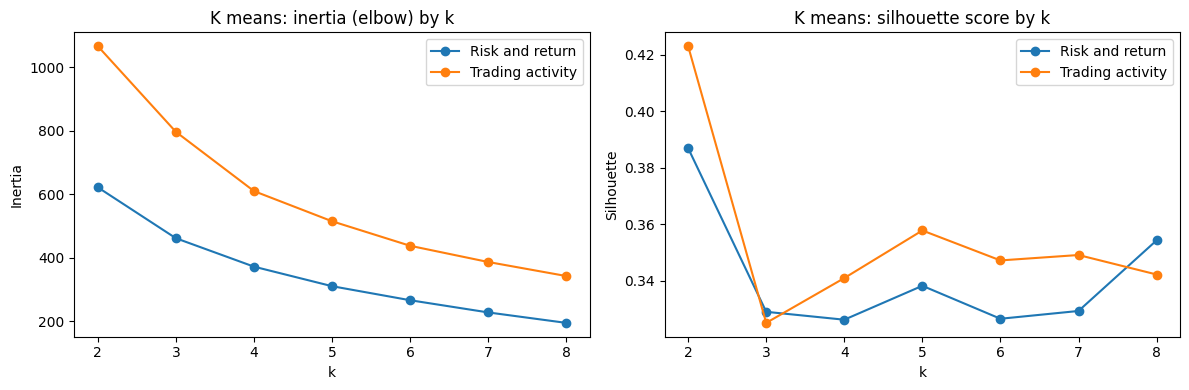

In [134]:
#  Elbow and silhouette plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for t, name in [(km_rr_table, 'Risk and return'), (km_rfm_table, 'Trading activity')]:
    axes[0].plot(t.index, t['inertia'], marker='o', label=name)
    axes[1].plot(t.index, t['silhouette'], marker='o', label=name)
axes[0].set_title('K means: inertia (elbow) by k'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].set_title('K means: silhouette score by k'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
axes[0].legend(); axes[1].legend()
plt.tight_layout()
plt.savefig('task2_3_kmeans_k_selection.png', dpi=150)
plt.show()

In [135]:
# store selected K means risk-return clusters
common['KMeans_RR'] = km_rr_labels[k_km_rr]
# store selected K means trading-activity clusters
common['KMeans_RFM'] = km_rfm_labels[k_km_rfm]
km_rr_table.to_csv('task2_3_kmeans_rr_k_table.csv')
km_rfm_table.to_csv('task2_3_kmeans_rfm_k_table.csv')

In [136]:
# Four baseline solutions: one row per share, same common share set
assignments = common[['Security', 'GICS Sector'] + rr_cols + rfm_cols +
                     ['Ward_RR', 'KMeans_RR', 'Ward_RFM', 'KMeans_RFM']]
assignments.to_csv('task2_cluster_assignments.csv')
print('\nCluster assignments saved for', len(assignments), 'shares')
print(assignments.head())


Cluster assignments saved for 486 shares
                    Security             GICS Sector  Mean_Weekly_Return      Beta  Recency  Frequency      Monetary  Ward_RR  KMeans_RR  Ward_RFM  KMeans_RFM
Ticker                                                                                                                                                        
A       Agilent Technologies             Health Care            0.001121  1.074723       11          2  1.400180e+10        2          2         2           1
AAPL              Apple Inc.  Information Technology            0.003930  1.174836       11          2  6.233034e+11        1          1         2           1
ABBV                  AbbVie             Health Care            0.003749  0.425365       11          3  6.837054e+10        2          2         2           1
ABNB                  Airbnb  Consumer Discretionary            0.001475  1.472709       11          3  3.652850e+10        2          1         2           1
ABT 

In [137]:
# Task 2.4  Cluster profiles and algorithm comparison

In [138]:
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score

In [139]:
def full_profile(label_col, cols):
    g = common.groupby(label_col)
    p = g[cols].agg(['mean', 'median'])             # mean and median of each feature in original units
    p.columns = [a + '_' + b for a, b in p.columns]
    p.insert(0, 'n_shares', g.size())               # cluster size
    return p
profiles = {}
for col, cols in [('Ward_RR', rr_cols), ('KMeans_RR', rr_cols),
                  ('Ward_RFM', rfm_cols), ('KMeans_RFM', rfm_cols)]:
    profiles[col] = full_profile(col, cols)
    print(f'\nProfile {col} (original units; Monetary in USD over 60 sessions):')
    print(profiles[col].round(4))
    profiles[col].to_csv(f'task2_4_profile_{col}.csv')


Profile Ward_RR (original units; Monetary in USD over 60 sessions):
         n_shares  Mean_Weekly_Return_mean  Mean_Weekly_Return_median  Beta_mean  Beta_median
Ward_RR                                                                                      
1              92                   0.0063                     0.0055     1.2981       1.2177
2             394                   0.0020                     0.0021     0.8979       0.8817

Profile KMeans_RR (original units; Monetary in USD over 60 sessions):
           n_shares  Mean_Weekly_Return_mean  Mean_Weekly_Return_median  Beta_mean  Beta_median
KMeans_RR                                                                                      
1               143                   0.0053                     0.0049     1.3505       1.2781
2               343                   0.0018                     0.0019     0.8166       0.8340

Profile Ward_RFM (original units; Monetary in USD over 60 sessions):
          n_shares  Recency_me

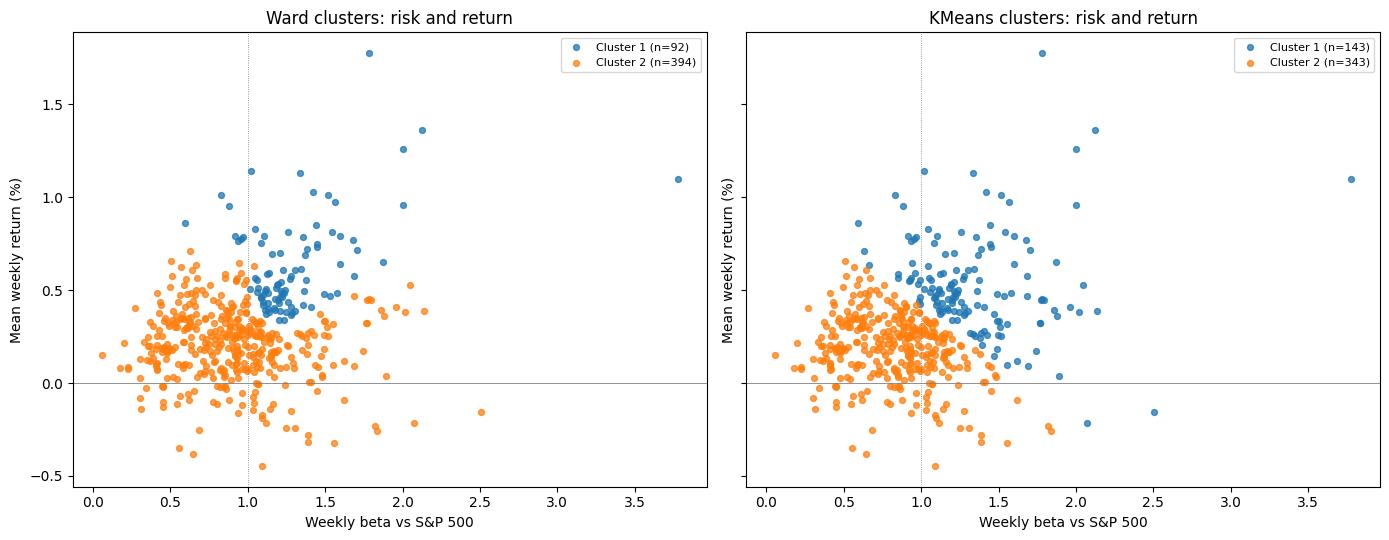

In [140]:
#  Labelled 2D visualisation: risk and return (original units)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, col in zip(axes, ['Ward_RR', 'KMeans_RR']):
    for c in sorted(common[col].unique()):
        d = common[common[col] == c]
        ax.scatter(d['Beta'], d['Mean_Weekly_Return'] * 100, s=18, alpha=0.75, label=f'Cluster {c} (n={len(d)})')
    ax.axhline(0, color='grey', lw=0.6); ax.axvline(1, color='grey', lw=0.6, ls=':')
    ax.set_xlabel('Weekly beta vs S&P 500')
    ax.set_ylabel('Mean weekly return (%)')
    ax.set_title(col.replace('_RR', '') + ' clusters: risk and return')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('task2_4_risk_return_clusters.png', dpi=150)
plt.show()


PCA on standardised R, F, log1p(M): explained variance ratio [0.458 0.336] | total 0.794
PCA loadings (how each feature builds each axis):
                  PC1    PC2
Recency         0.711  0.023
Frequency      -0.650  0.402
log1p_Monetary  0.268  0.915


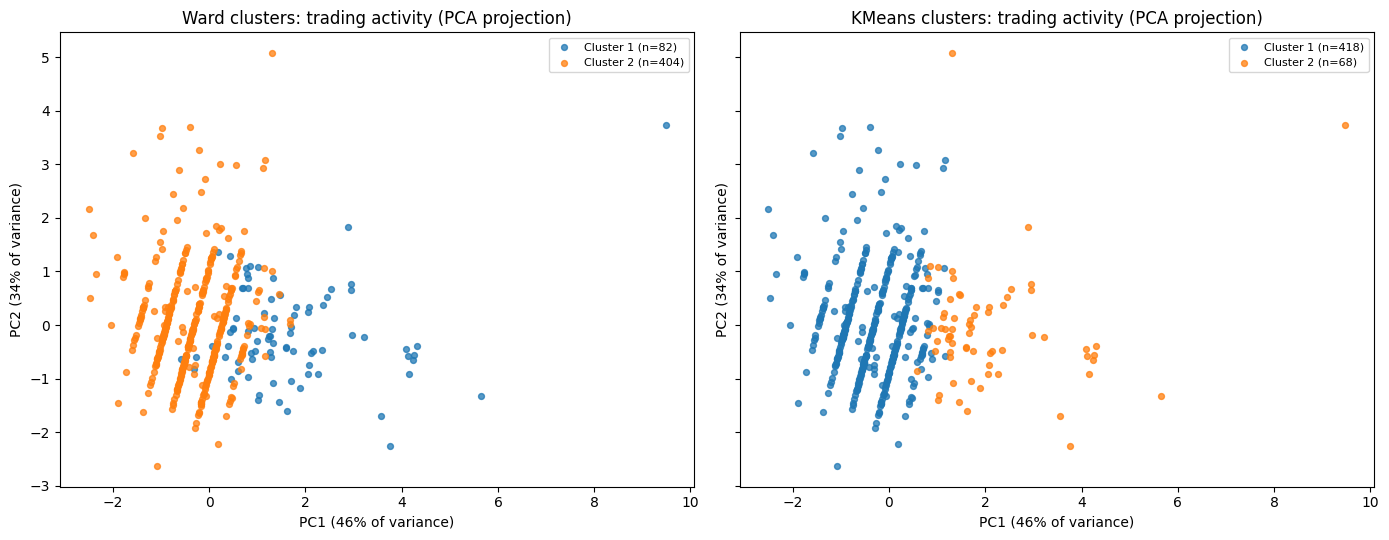

In [141]:
# Labelled 2D visualisation: trading activity via PCA
pca = PCA(n_components=2, random_state=SEED)
# same standardised data used for clustering
pcs = pca.fit_transform(Z_rfm.values)
print('\nPCA on standardised R, F, log1p(M): explained variance ratio',
      pca.explained_variance_ratio_.round(3), '| total', pca.explained_variance_ratio_.sum().round(3))
print('PCA loadings (how each feature builds each axis):')
print(pd.DataFrame(pca.components_.T, index=Z_rfm.columns, columns=['PC1', 'PC2']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, col in zip(axes, ['Ward_RFM', 'KMeans_RFM']):
    for c in sorted(common[col].unique()):
        m = (common[col] == c).values
        ax.scatter(pcs[m, 0], pcs[m, 1], s=18, alpha=0.75, label=f'Cluster {c} (n={m.sum()})')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)')
    ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
    ax.set_title(col.replace('_RFM', '') + ' clusters: trading activity (PCA projection)')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('task2_4_rfm_clusters_pca.png', dpi=150)
plt.show()

In [142]:
# ---- Algorithm comparison on the same shares ----
# ARI ignores the arbitrary cluster numbers. The crosstab shows where the methods disagree.
for a, b in [('Ward_RR', 'KMeans_RR'), ('Ward_RFM', 'KMeans_RFM')]:
    print(f'\n{a} vs {b}: ARI = {adjusted_rand_score(common[a], common[b]):.3f}')
    print(pd.crosstab(common[a], common[b]))


Ward_RR vs KMeans_RR: ARI = 0.598
KMeans_RR   1    2
Ward_RR           
1          92    0
2          51  343

Ward_RFM vs KMeans_RFM: ARI = 0.700
KMeans_RFM    1   2
Ward_RFM           
1            22  60
2           396   8


In [143]:
# Task 2.5  RFM sensitivity and correlated inputs

In [144]:
from sklearn.metrics import adjusted_rand_score

In [145]:
# ---------- 2.5.1 Correlation analysis ----------
rfm_log = X_rfm[['Recency', 'Frequency', 'log1p_Monetary']]
corr_pearson = rfm_log.corr(method='pearson')
print('Pearson correlation, R, F, log1p(M):'); print(corr_pearson.round(3))
corr_pearson.to_csv('task2_5_rfm_correlations.csv')

Pearson correlation, R, F, log1p(M):
                Recency  Frequency  log1p_Monetary
Recency           1.000     -0.346           0.152
Frequency        -0.346      1.000           0.013
log1p_Monetary    0.152      0.013           1.000


In [146]:
# ---------- 2.5.2 Removal of Monetary ----------
X_rf = common[['Recency', 'Frequency']].copy()
if LOG_RECENCY:
    X_rf['Recency'] = np.log1p(X_rf['Recency'])        # same treatment as the full model
Z_rf = pd.DataFrame(StandardScaler().fit_transform(X_rf), index=X_rf.index, columns=X_rf.columns)  # fresh scaling
link_rf = linkage(Z_rf.values, method='ward', metric='euclidean')
common['Ward_RF_only'] = fcluster(link_rf, t=k_ward_rfm, criterion='maxclust')   # same k as selected Ward RFM
assert Z_rf.index.equals(Z_rfm.index)                     # same shares
ari = adjusted_rand_score(common['Ward_RFM'], common['Ward_RF_only'])
print(f'\nWard RFM vs Ward R+F only (k = {k_ward_rfm}, {len(common)} shares): ARI = {ari:.3f}')
print('\nMembership crosstab (rows = with Monetary, columns = without Monetary):')
print(pd.crosstab(common['Ward_RFM'], common['Ward_RF_only'], margins=True))


Ward RFM vs Ward R+F only (k = 2, 486 shares): ARI = 0.873

Membership crosstab (rows = with Monetary, columns = without Monetary):
Ward_RF_only   1    2  All
Ward_RFM                  
1             79    3   82
2             10  394  404
All           89  397  486



Traded value profile WITH Monetary:
          n_shares  Recency_mean  Frequency_mean  Monetary_median_USD_bn  Monetary_mean_USD_bn
Ward_RFM                                                                                      
1               82        58.305           2.098                  17.849                47.159
2              404        12.715           3.171                  16.047                37.830

Traded value profile WITHOUT Monetary:
              n_shares  Recency_mean  Frequency_mean  Monetary_median_USD_bn  Monetary_mean_USD_bn
Ward_RF_only                                                                                      
1                   89        56.562           2.011                  20.848                46.530
2                  397        12.302           3.209                  15.464                37.807


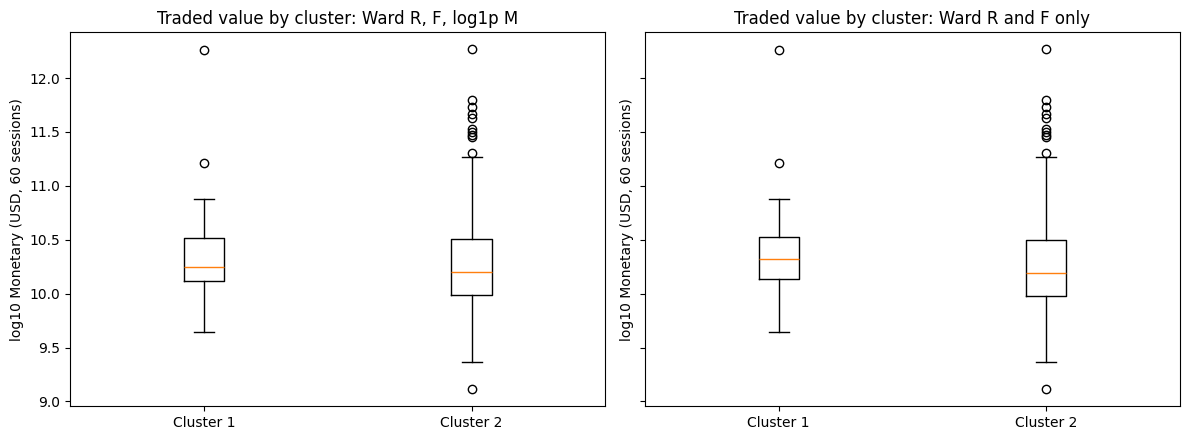

In [147]:
# Traded value (Monetary, liquidity proxy) profiles of both solutions
def traded_value_profile(label_col):
    g = common.groupby(label_col)
    return pd.DataFrame({'n_shares': g.size(),
                         'Recency_mean': g['Recency'].mean(),
                         'Frequency_mean': g['Frequency'].mean(),
                         'Monetary_median_USD_bn': g['Monetary'].median() / 1e9,
                         'Monetary_mean_USD_bn': g['Monetary'].mean() / 1e9})
tv_full = traded_value_profile('Ward_RFM')
tv_rf = traded_value_profile('Ward_RF_only')
print('\nTraded value profile WITH Monetary:'); print(tv_full.round(3))
print('\nTraded value profile WITHOUT Monetary:'); print(tv_rf.round(3))
tv_full.to_csv('task2_5_traded_value_with_M.csv'); tv_rf.to_csv('task2_5_traded_value_without_M.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, col, title in [(axes[0], 'Ward_RFM', 'Ward R, F, log1p M'), (axes[1], 'Ward_RF_only', 'Ward R and F only')]:
    groups = sorted(common[col].unique())
    ax.boxplot([np.log10(common.loc[common[col] == c, 'Monetary']) for c in groups])
    ax.set_xticks(range(1, len(groups) + 1)); ax.set_xticklabels([f'Cluster {c}' for c in groups])
    ax.set_title(f'Traded value by cluster: {title}')
    ax.set_ylabel('log10 Monetary (USD, 60 sessions)')
plt.tight_layout()
plt.savefig('task2_5_traded_value_by_cluster.png', dpi=150)
plt.show()

In [148]:
common.to_csv('task2_feature_table_with_clusters.csv')
print('\nFinal table saved: task2_feature_table_with_clusters.csv')


Final table saved: task2_feature_table_with_clusters.csv



Ward_RR profile (medians, original units):
         Mean_Weekly_Return      Beta  Recency  Frequency      Monetary  n_shares
Ward_RR                                                                          
1                  0.005503  1.217711     11.0        3.0  2.418413e+10        92
2                  0.002093  0.881696     11.0        3.0  1.532516e+10       394

Ward_RR sector composition (% of each cluster):
Ward_RR                    1     2
GICS Sector                       
Communication Services   5.4   3.8
Consumer Discretionary  12.0   9.1
Consumer Staples         0.0   8.1
Energy                   4.3   4.1
Financials              14.1  15.5
Health Care              2.2  14.2
Industrials             22.8  14.5
Information Technology  31.5  11.4
Materials                3.3   5.1
Real Estate              3.3   6.9
Utilities                1.1   7.4


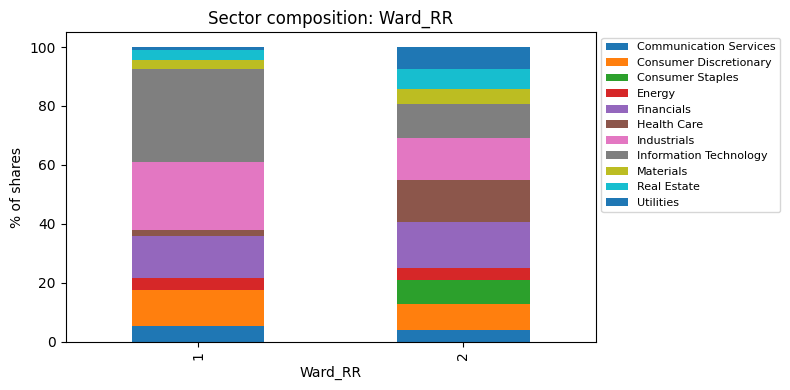


Ward_RFM profile (medians, original units):
          Mean_Weekly_Return      Beta  Recency  Frequency      Monetary  n_shares
Ward_RFM                                                                          
1                   0.002444  1.046557     54.5        2.0  1.784903e+10        82
2                   0.002689  0.935006     11.0        3.0  1.604728e+10       404

Ward_RFM sector composition (% of each cluster):
Ward_RFM                   1     2
GICS Sector                       
Communication Services   4.9   4.0
Consumer Discretionary  11.0   9.4
Consumer Staples         8.5   6.2
Energy                   2.4   4.5
Financials              12.2  15.8
Health Care             11.0  12.1
Industrials              7.3  17.8
Information Technology  22.0  13.9
Materials                9.8   3.7
Real Estate              0.0   7.4
Utilities               11.0   5.2


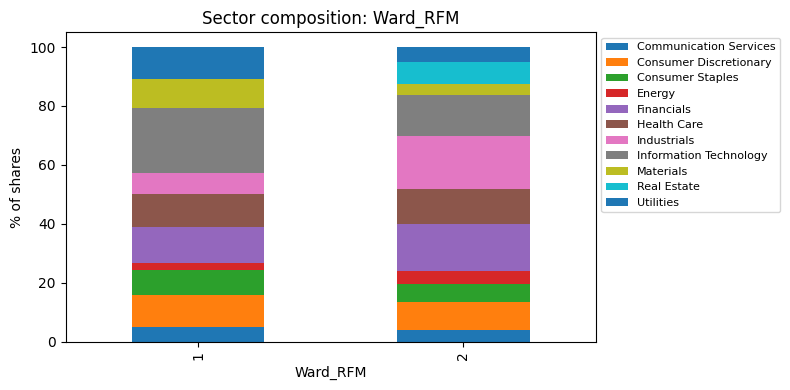


Shares in each risk-return cluster (rows) x RFM cluster (columns):
Ward_RFM   1    2
Ward_RR          
1         19   73
2         63  331


In [149]:
# Task 3.2.1  Cluster profiles and sector composition
# Weekly return / beta clusters (Ward_RR) compared with RFM clusters (Ward_RFM).
for col in ['Ward_RR', 'Ward_RFM']:
    print(f'\n{col} profile (medians, original units):')
    print(common.groupby(col)[rr_cols + rfm_cols].median().assign(n_shares=common[col].value_counts()))
    sector_pct = pd.crosstab(common['GICS Sector'], common[col], normalize='columns') * 100
    print(f'\n{col} sector composition (% of each cluster):')
    print(sector_pct.round(1))
    sector_pct.T.plot(kind='bar', stacked=True, figsize=(8, 4), title=f'Sector composition: {col}')
    plt.ylabel('% of shares'); plt.legend(bbox_to_anchor=(1, 1), fontsize=8)
    plt.tight_layout(); plt.savefig(f'task3_2_1_sectors_{col}.png', dpi=150); plt.show()
print('\nShares in each risk-return cluster (rows) x RFM cluster (columns):')
print(pd.crosstab(common['Ward_RR'], common['Ward_RFM']))